# Topic Modeling
### Bert Sentence Embedding, LDA, and K-means Clustering

##### Concatenate the sentence embeddings with LDA, use an autoencoder to get the latent representation and perform K-means to perform clustering on the data

In [1]:
#importing all dependencies.
import os
import pandas as pd
import numpy as np

import gensim
from gensim import corpora, models

from datetime import datetime

%matplotlib inline
import matplotlib.pyplot as plt

from nltk.tokenize import word_tokenize

from collections import Counter

import umap
from wordcloud import WordCloud

import torch
from torch import nn

from sklearn.cluster import KMeans

/home/anum/anaconda3/envs/nlp/lib/python3.8/site-packages/umap/spectral.py:4: NumbaDeprecationWarning: No direct replacement for 'numba.targets' available. Visit https://gitter.im/numba/numba-dev to request help. Thanks!
  import numba.targets


#### Text Related Utility Functions

In [2]:
from utils.utility_functions import *

In [3]:
def preprocess_word(s):
    """
    Get word level preprocessed data from preprocessed sentences
    including: remove punctuation, select noun, stem, stop_words
    :param s: sentence to be processed
    :return: word level pre-processed list
    """
    w_list = word_tokenize(s)
    w_list = f_punct(w_list)
    w_list = f_noun(w_list)
    w_list = f_stem(w_list)
    w_list = f_stopw(w_list)

    return w_list


In [4]:
def preprocess_sent(t):
    """
    Get sentence level preprocessed data from raw texts
    :param t: review to be processed
    :return: text after sentence level preprocessing
    """
    s = sentence_clean(t)
    return s


In [5]:
def preprocess_documents(file=None):
    """
    Read the file and preprocess the data
    
    file(str): path to the input file
    """

    
    print('Reading the file')
    documents = pd.read_csv(file)
    docs= documents.paragraph
    n_docs = len(docs)
    
    print('Preprocessing raw texts')
    
    sentences = []  # sentence level preprocessed
    token_lists = []  # word level preprocessed
    
    for idx in range(n_docs):
        sentence = preprocess_sent(docs[idx])
        token_list = preprocess_word(sentence)

        sentences.append(sentence)
        token_lists.append(token_list)
    
    print('Preprocessing raw texts. Done!')
    return sentences, token_lists


### Reading the data and preprocessing it

In [6]:
# Input file
file = 'data/sample_text.txt'

In [7]:
sentences, token_lists = preprocess_documents(file)

Reading the file
Preprocessing raw texts
Preprocessing raw texts. Done!


In [8]:
sentences

['this a very nice blouse',
 'this a shitty jeans and i would never order from zalando again. i want my money back',
 'we all live in munich.',
 'alice in wonderland',
 'life is good.',
 'alice is not in wonderland',
 'i hate you',
 'i love this new blouse and the colors are very vibrant and amazing i love it',
 'i am happy',
 'harry ron and hermione are best friends',
 'i am sad',
 'i am sad',
 'i am very excited',
 'i am overjoyed',
 'you are the best',
 'you are the worst']

### Preparing autoencoder class

In [9]:
from models.autoencoder_model import model as ae_model

class Autoencoder():
    def __init__(self, latent_dim=32, epochs=5, batch_size=2, input_dim = 1026):
        self.history = []
        self.model = ae_model(latent_dim, input_dim)
        self.num_epochs = epochs
        
        
    def fit(self, X):
        
        learning_rate = 1e-3
        criterion = nn.MSELoss()
        optimizer = torch.optim.Adam(self.model.parameters(), lr=learning_rate, weight_decay=1e-5)
        
        train_loss = []
        
        
        for epoch in range(self.num_epochs):

            for data in X:
                d = torch.tensor(data)
                d = torch.autograd.Variable(d)
                d = d.unsqueeze(0)
                
                # forward pass
                output = self.model(d.float())
                loss = criterion(output, d.float())

                
                # backward pass
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
    
            # log
            loss = loss.item()            
            train_loss.append(loss)
            print('Epoch {} of {}, Train Loss: {:.3f}'.format(epoch+1, self.num_epochs, loss))



### Preparing the Topic Model Class

In [10]:
# Importing the embeddings codes
from models.embeddings_model import get_embeddings

class Topic_Model:
    def __init__(self, k=3):
        """
        :param k: number of topics
        :param method: method chosen for the topic model
        """

        
        self.k = k
        self.dictionary = None
        self.corpus = None
        self.cluster_model = None
        self.ldamodel = None
        self.vec = {}
        self.gamma = 15  # parameter for reletive importance of lda
        self.method = "LDA_BERT"
        self.AE = None
        self.id = self.method + '_' + datetime.now().strftime("%Y_%m_%d_%H_%M_%S")


    def vectorize(self, sentences, token_lists, method=None):
        """
        Get vector representations from selected methods
        """
        
        
        if method == 'LDA':
            
            # turn tokenized documents into a id <-> term dictionary
            self.dictionary = corpora.Dictionary(token_lists)
            # convert tokenized documents into a document-term matrix
            self.corpus = [self.dictionary.doc2bow(text) for text in token_lists]
            
            print('Getting vector representations for LDA ')
            if not self.ldamodel:
                self.ldamodel = gensim.models.ldamodel.LdaModel(self.corpus, num_topics=self.k, id2word=self.dictionary,
                                                                passes=20)

            def get_vec_lda(model, corpus, k):
                """
                Get the LDA vector representation (probabilistic topic assignments for all documents)
                :return: vec_lda with dimension: (n_doc * n_topic)
                """
                n_doc = len(corpus)
                vec_lda = np.zeros((n_doc, k))
                for i in range(n_doc):
                    # get the distribution for the i-th document in corpus
                    for topic, prob in model.get_document_topics(corpus[i]):
                        vec_lda[i, topic] = prob

                return vec_lda

            vec = get_vec_lda(self.ldamodel, self.corpus, self.k)
            print('Getting vector representations for LDA. Done!')
            return vec

        elif method == 'BERT':

            print('Getting vector representations for BERT ')

            bert_sentence_embedding = get_embeddings(file,'bert')
            vec = np.array(bert_sentence_embedding)
            
            print('Getting vector representations for BERT. Done!')
            return vec
             
        elif method == 'LDA_BERT':
            
            # Get probability of a text belonging to a class from LDA
            vec_lda = self.vectorize(sentences, token_lists, method='LDA')
            
            # Get sentence level embedding from Bert
            vec_bert = self.vectorize(sentences, token_lists, method='BERT')
            
            #Concatenat them
            vec_ldabert = np.c_[vec_lda * self.gamma, vec_bert]
            self.vec['LDA_BERT'] = vec_ldabert
            
            
            if not self.AE:
                # Learn the latent representation of data
                input_size = vec_lda.shape[1] + vec_bert.shape[1]
                self.AE = Autoencoder(latent_dim = 32, input_dim =  input_size)
                print('Fitting Autoencoder')
                self.AE.fit(vec_ldabert)
                print('Fitting Autoencoder Done!') 
            
            vec = self.AE.model.predict(vec_ldabert)
            return vec

    def fit(self, sentences, token_lists, method=None, m_clustering=None):
        """
        Fit the topic model for selected method given the preprocessed data
        :docs: list of documents, each doc is preprocessed as tokens
        :return:
        """

        #use kmeans clustering to cluster the latent representations
        m_clustering = KMeans
        self.cluster_model = m_clustering(self.k)

        print('Clustering the latent representations')
        
        self.vec[method] = self.vectorize(sentences, token_lists, self.method)
        
        self.cluster_model.fit(self.vec[method])
        
        print('Clustering. Done!')


## The Magic Begins here

In [11]:
# Define the topic model object
TopicModelObject = Topic_Model(k = 3)

In [12]:
# Fit the topic model
TopicModelObject.fit(sentences, token_lists)

Clustering the latent representations
Getting vector representations for LDA 
Getting vector representations for LDA. Done!
Getting vector representations for BERT 
Our final sentence embedding vector of shape: torch.Size([16, 1024])
Getting vector representations for BERT. Done!
Fitting Autoencoder
Epoch 1 of 5, Train Loss: 0.136
Epoch 2 of 5, Train Loss: 0.076
Epoch 3 of 5, Train Loss: 0.064
Epoch 4 of 5, Train Loss: 0.062
Epoch 5 of 5, Train Loss: 0.061
Fitting Autoencoder Done!
Clustering. Done!


In [13]:
labels = set(TopicModelObject.cluster_model.labels_)
for label in labels:
    index = []
    for idx, l in enumerate(TopicModelObject.cluster_model.labels_):
        if l == label:
            index.append(idx)
    print ('\n \nSentences belong to cluster ', str (label+1), ' are: \n ')
    for i in index:
        print (sentences[i])


 
Sentences belong to cluster  1  are: 
 
this a shitty jeans and i would never order from zalando again. i want my money back
we all live in munich.
life is good.
i love this new blouse and the colors are very vibrant and amazing i love it

 
Sentences belong to cluster  2  are: 
 
this a very nice blouse
i hate you
i am happy
i am sad
i am sad
i am very excited
i am overjoyed
you are the best
you are the worst

 
Sentences belong to cluster  3  are: 
 
alice in wonderland
alice is not in wonderland
harry ron and hermione are best friends


## Visualizations

In [14]:
def plot_proj(embedding, lbs):
    """
    Plot UMAP embeddings
    :param embedding: UMAP (or other) embeddings
    :param lbs: labels
    """
    n = len(embedding)
    counter = Counter(lbs)
    for i in range(len(np.unique(lbs))):
        plt.plot(embedding[:, 0][lbs == i], embedding[:, 1][lbs == i], '.', alpha=0.5,
                 label='cluster {}: {:.2f}%'.format(i, counter[i] / n * 100))
    plt.legend(loc = 'best')
    plt.grid(color ='grey', linestyle='-',linewidth = 0.25)


In [15]:

def get_wordcloud(model, token_lists, topic):
    """
    Get word cloud of each topic from fitted model
    :param model: Topic_Model object
    :param sentences: preprocessed sentences from docs
    """

    print('Getting wordcloud for topic {} ...'.format(topic))
    lbs = model.cluster_model.labels_
    tokens = ' '.join([' '.join(_) for _ in np.array(token_lists)[lbs == topic]])

    wordcloud = WordCloud(width=800, height=560,
                          background_color='white', collocations=False,
                          min_font_size=10).generate(tokens)

    # plot the WordCloud image
    plt.figure(figsize=(8, 5.6), facecolor=None)
    plt.imshow(wordcloud)
    plt.axis("off")
    plt.tight_layout(pad=0)
    dr = 'output/{}/{}'.format(model.method, model.id)
    if not os.path.exists(dr):
        os.makedirs(dr)
    plt.savefig('output/{}/{}/'.format(model.method, model.id) + 'Topic' + str(topic) + '_wordcloud')
    print('Getting wordcloud for topic {}. Done!'.format(topic))

In [16]:
def visualize(model):
    """
    Visualize the result for the topic model by 2D embedding (UMAP)
    :param model: Topic_Model object
    """
    reducer = umap.UMAP()
    print('Calculating UMAP projection ...')
    vec_umap = reducer.fit_transform(model.vec[model.method])
    print('Calculating UMAP projection. Done!')
    plot_proj(vec_umap, model.cluster_model.labels_)
    dr = 'output/{}/{}'.format(model.method, model.id)
    print (dr)
    if not os.path.exists(dr):
        os.makedirs(dr)
    plt.savefig('output/{}/{}/2dvis.png'.format(model.method, model.id))

Calculating UMAP projection ...
Calculating UMAP projection. Done!
output/LDA_BERT/LDA_BERT_2020_05_21_14_56_03
Getting wordcloud for topic 0 ...
Getting wordcloud for topic 0. Done!
Getting wordcloud for topic 1 ...
Getting wordcloud for topic 1. Done!
Getting wordcloud for topic 2 ...
Getting wordcloud for topic 2. Done!


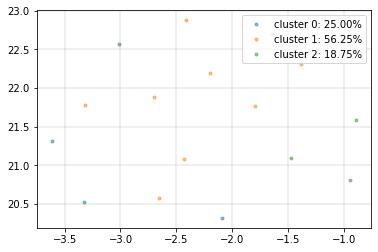

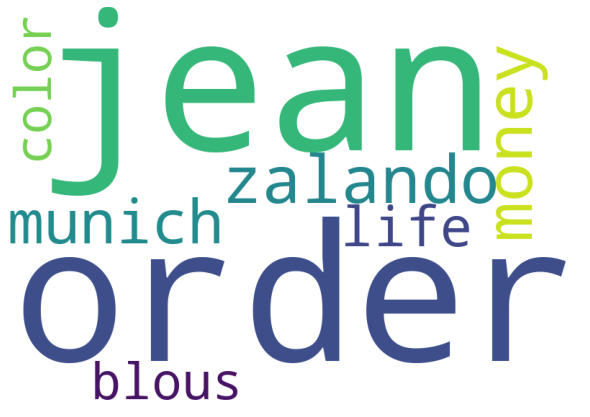

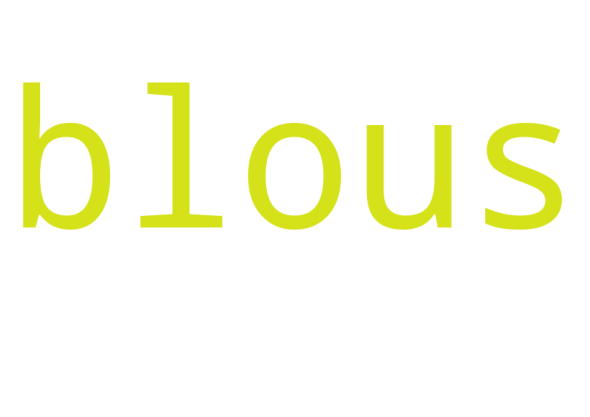

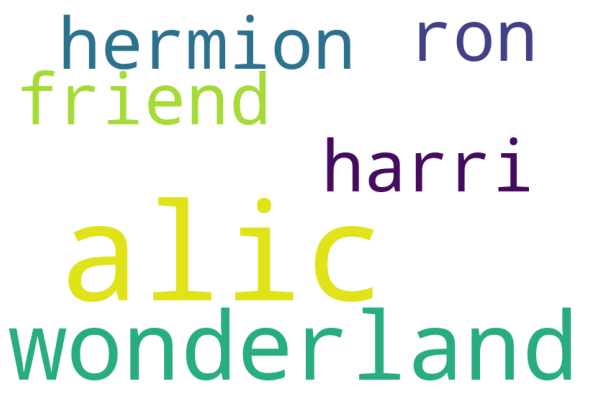

In [17]:
# visualize and save img
visualize(TopicModelObject)
for i in range(TopicModelObject.k):
    get_wordcloud(TopicModelObject, token_lists, i)

